# <DEVICE> — Analysis

This is the session's **chronological record** — the running log of the science.
Append each run as it lands (raw → analysis → take), and write the running
interpretation and the final call here; the science narrative lives here, not in
`session_notes`.

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [3]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    plot_raw,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a step / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from the session's gate calibration once the CNP
/ D-line is live.

In [4]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — establish the session's gate calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 9.5e-9    # top-gate hBN thickness, m    # <-- validate
t_bg = 11e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from the session's gate calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)


## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run** (`plot_raw(g)`); **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook reads as a **chronological log** — each run appended in time order as it lands (raw → analysis → take), following the four-cell rhythm below — and the session's call/verdict goes here too.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
plot_raw(g)                   # raw view FIRST — rails/clipping, dead channels, streaks live here

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Run 0 — gate-C liveness: TG sweep at V_bg = 0 (plan step 0)

Why: confirm the provided pair (source T_0 → drain B_3, sr1 = B_1−B_2) is alive inside the committed box, get the Rxx scale, a first CNP sighting, and the per-point timing (641 pts in ~3.3 min → 0.31 s/pt at τ = 30 ms, delay 0.2 s).

run 0
  type:    1D sweep
  recipe:  gate-c-liveness
  tags:    TG 0->-0.3->1.0->-0.3->0 V @5mV, delay 0.2 s, tau 30 ms; V_bg=0, V_si=0, B=0; I_bias 10 nA
  rows:    641 of 641 (complete)
  swept:   k_2400_tg_volt 0 → 0 (non-monotonic)


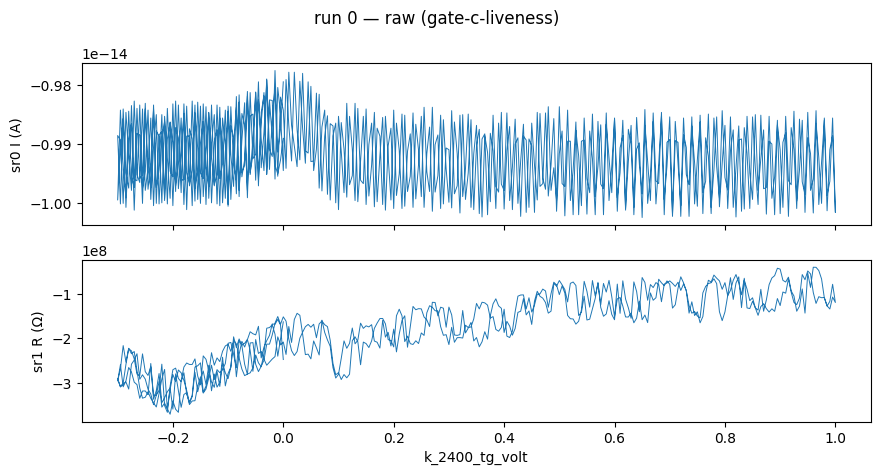

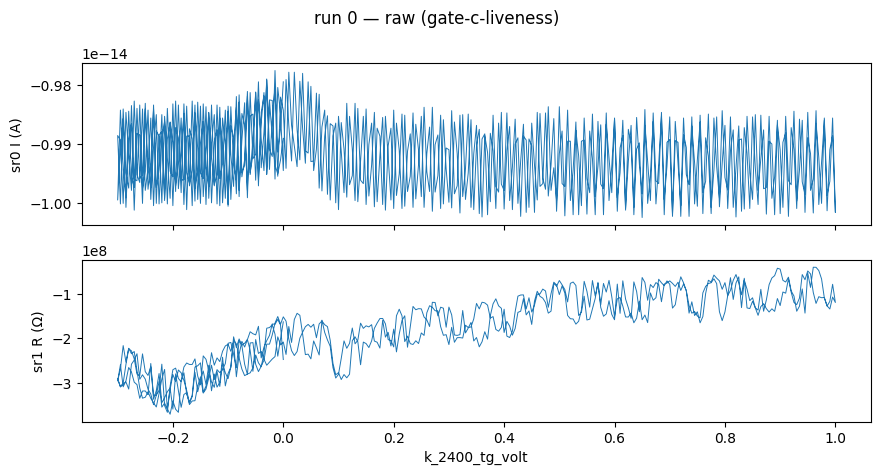

In [5]:
g = run(0)
print(summarize_run(g))
plot_raw(g)


I_drain med 9.92 nA; |Rxx| med 177 Ω (min 41, max 370)
I_tg med -95 pA (std 55); I_bg med 25 pA (std 35)


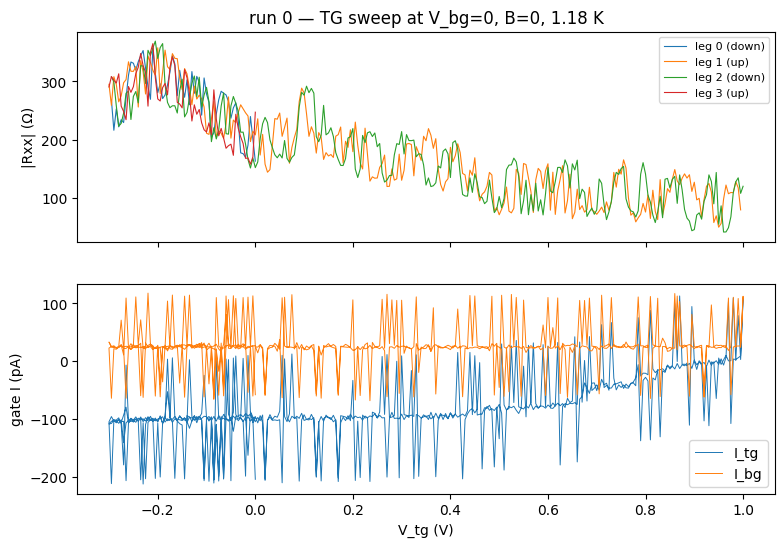

In [6]:
# Run 0: note sr0_X was stored already gain-divided (fp gain -1e6) — later runs store raw volts.
mc = g.meta["measurement_config"]
x = g.col("k_2400_tg_volt"); I = g.col("sr0_X"); R = g.col("sr1_X") / I
itg, ibg = g.col("k_2400_tg_curr"), g.col("k_2400_bg_curr")
dx = np.sign(np.diff(x)); legs = np.split(np.arange(len(x)), np.where(np.diff(dx) != 0)[0] + 1)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for k, leg in enumerate(legs):
    if len(leg) > 5:
        ax[0].plot(x[leg], np.abs(R[leg]), lw=0.8, label=f"leg {k} ({'up' if dx[leg[0]] > 0 else 'down'})")
ax[0].set_ylabel("|Rxx| (Ω)"); ax[0].legend(fontsize=8); ax[0].set_title("run 0 — TG sweep at V_bg=0, B=0, 1.18 K")
ax[1].plot(x, itg * 1e12, lw=0.7, label="I_tg"); ax[1].plot(x, ibg * 1e12, lw=0.7, label="I_bg")
ax[1].set_ylabel("gate I (pA)"); ax[1].set_xlabel("V_tg (V)"); ax[1].legend()
print(f"I_drain med {np.median(I)*1e9:.2f} nA; |Rxx| med {np.median(np.abs(R)):.0f} Ω (min {np.abs(R).min():.0f}, max {np.abs(R).max():.0f})")
print(f"I_tg med {np.median(itg)*1e12:.0f} pA (std {np.std(itg)*1e12:.0f}); I_bg med {np.median(ibg)*1e12:.0f} pA (std {np.std(ibg)*1e12:.0f})")


**Read (run 0):** pair alive — I_drain 9.92 nA (10 nA bias, phase 172°), stable to 1 %. |Rxx| is only 40–370 Ω across the full TG box at V_bg = 0: monotonic decrease from ≈300 Ω (V_tg = −0.3) to ≈100 Ω (V_tg = 1.0), a weak hump at V_tg ≈ −0.2 V (≈330 Ω), no CNP peak → the CNP is not in this cut (at V_bg = 0 the box spans n ≈ −0.5…+1.75e12 cm⁻² by geometry; the device looks electron-doped, CNP at V_tg < −0.3 V or at V_bg < 0). No hysteresis between legs. Gate currents: I_tg ≈ −100 pA offset drifting to 0 at +1 V (ohmic, ≈10 GΩ, Keithley-offset scale), I_bg ≈ +25 pA, single-point ±100 pA glitches = NPLC-1 noise, no leakage. Noise: ±50 Ω on a 2–3 µV signal with a periodic ripple on I and phase — interference through the 30 ms filter; τ → 100 ms from run 1. Also run 0 stored sr0_X already gain-divided (fp gain −1e6 on top of mc sr0_gain) — later runs store raw volts so hera-watch / resistance_grids divide once.

## Run 1 — BG sweep at V_tg = 0 (plan step 1)

Why: run 0 had no CNP in the TG cut at V_bg = 0; the back gate reaches further into the hole side (n ≈ −2e12 cm⁻² at V_bg = −1.3 by geometry). τ raised to 100 ms (delay 0.5 s, 0.68 s/pt); lock-in X now stored raw.

run 1
  type:    1D sweep
  recipe:  bg-sweep-1d
  tags:    BG 0->2.0->-1.3->0 V @10mV (661 pts), delay 0.5 s, tau 100 ms; V_tg=0, V_si=0, B=0; I_bias 10 nA
  rows:    661 of 661 (complete)
  swept:   k_2400_bg_volt 0 → 0 (non-monotonic)


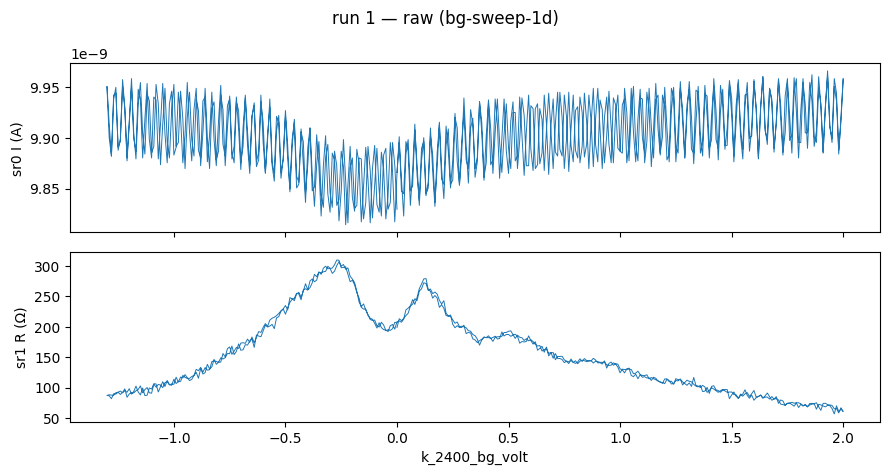

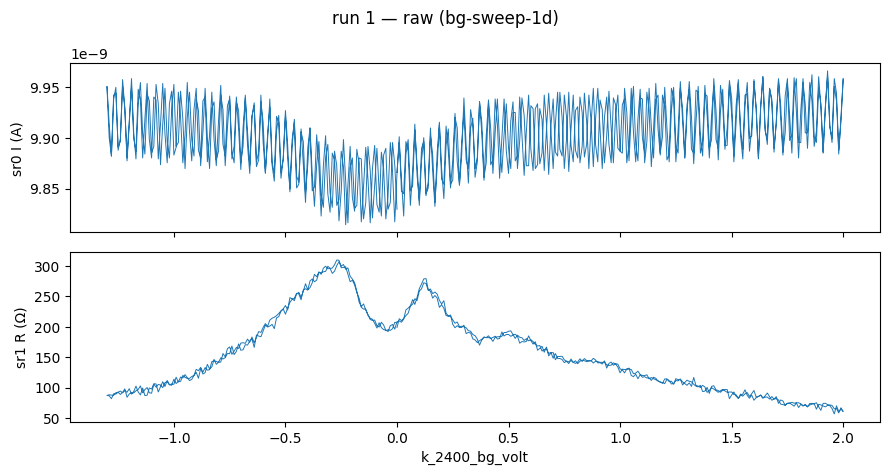

In [7]:
g = run(1)
print(summarize_run(g))
plot_raw(g)


peak at V_bg = +0.510 V: 193 Ω
peak at V_bg = +0.130 V: 279 Ω
peak at V_bg = -0.270 V: 310 Ω
peak at V_bg = -1.170 V: 102 Ω
I_drain med 9.90 nA; |Rxx| range 57–310 Ω; hysteresis (up-down) med |ΔR| = 3.4 Ω


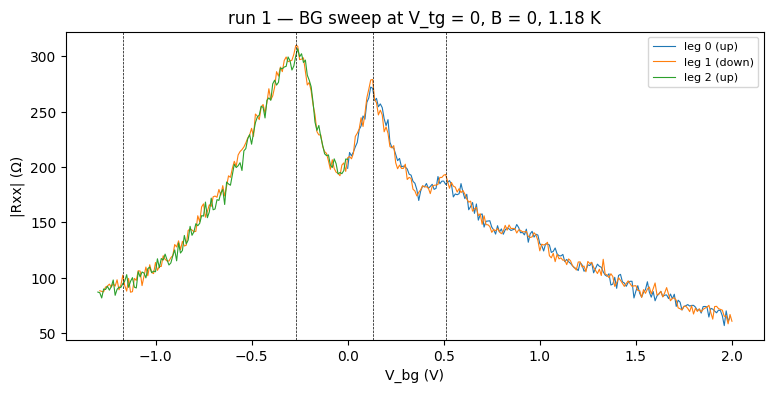

In [8]:
mc = g.meta["measurement_config"]
x = g.col("k_2400_bg_volt"); I = g.col("sr0_X") / mc["sr0_gain"]; R = g.col("sr1_X") / I
dx = np.sign(np.diff(x)); legs = np.split(np.arange(len(x)), np.where(np.diff(dx) != 0)[0] + 1)
fig, ax = plt.subplots(figsize=(9, 4))
for k, leg in enumerate(legs):
    if len(leg) > 5:
        ax.plot(x[leg], np.abs(R[leg]), lw=0.8, label=f"leg {k} ({'up' if dx[leg[0]] > 0 else 'down'})")
ax.set_xlabel("V_bg (V)"); ax.set_ylabel("|Rxx| (Ω)"); ax.legend(fontsize=8)
ax.set_title("run 1 — BG sweep at V_tg = 0, B = 0, 1.18 K")
from scipy.signal import find_peaks
leg = legs[1]; xs, rs = x[leg], np.abs(R[leg])
pk, _ = find_peaks(rs, prominence=15)
for p in pk:
    print(f"peak at V_bg = {xs[p]:+.3f} V: {rs[p]:.0f} Ω")
    ax.axvline(xs[p], color="k", lw=0.5, ls="--")
print(f"I_drain med {np.median(I)*1e9:.2f} nA; |Rxx| range {np.abs(R).min():.0f}–{np.abs(R).max():.0f} Ω; hysteresis (up-down) med |ΔR| = "
      f"{np.median(np.abs(np.interp(x[legs[0]], xs[::-1], rs[::-1]) - np.abs(R[legs[0]]))):.1f} Ω")


**Read (run 1):** clean, reproducible, no hysteresis (up/down legs overlay to ~2 Ω). |Rxx| runs 57–310 Ω. Two distinct maxima at V_tg = 0: **V_bg ≈ −0.25 V (310 Ω)** and **V_bg ≈ +0.12 V (275 Ω)**, plus a weak shoulder near +0.5 V; R falls monotonically to ~60 Ω at +2 V (electrons) and ~90 Ω at −1.3 V (holes). Peak contrast over the metallic background is only ~3× — a very conductive neutrality region. Two candidates: (i) two n = 0 lines from a doping step between B_1 and B_2 (they would run parallel in the gate map, ~0.37 V apart in V_bg ≈ 0.56e12 cm⁻² by geometry), or (ii) a single CNP plus a band-edge feature at finite D (features diverge with D). Run 2 (coarse map) discriminates. Gate currents unchanged (I_tg −100 pA offset, I_bg +25 pA, no V-dependence), I_drain 9.90 nA.

## Run 3 — coarse full-box gate map at B = 0 (plan step 2)

Why: locate the CNP line and its slope (c_bg/c_tg), the offsets, and the first look at R_CNP(D) and its D-symmetry; sort run 1's two peaks. (Run 2 is a 3-row stub — the live 2D-mesh plotter crashed; discard.)

run 3
  type:    2D sweep
  recipe:  gatemap-coarse
  tags:    megasweep BG slow 2.0->-1.3 V @100mV (34 rows) x TG fast -0.3->1.0 V @20mV (66 pts); slow_delay 1 s, fast_delay 0.5 s, tau 100 ms; V_si=0, B=0; I_bias 10 nA
  rows:    2244


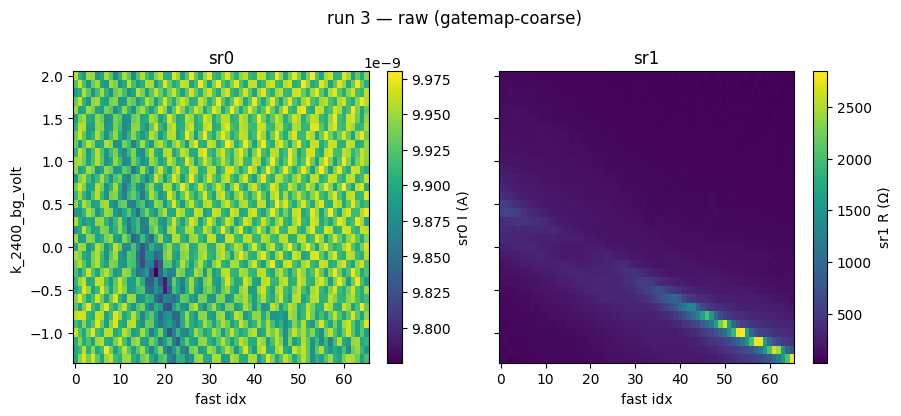

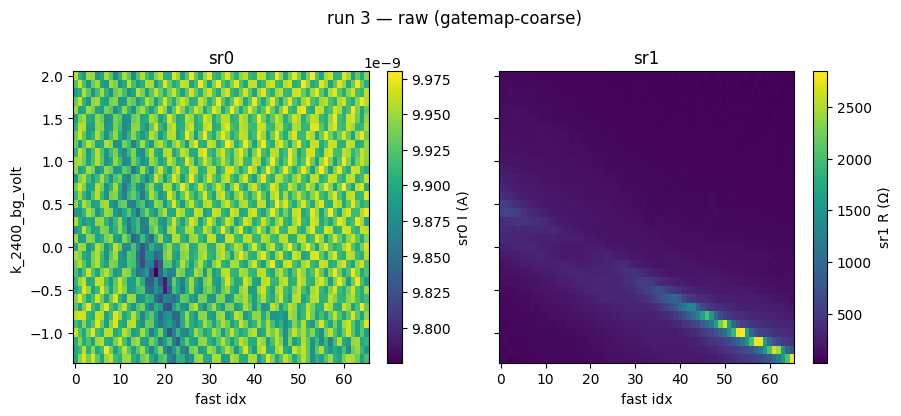

In [9]:
g = run(3)
print(summarize_run(g))
plot_raw(g)


CNP line (rows V_bg <= -0.2): V_tg = +0.061 -0.713*V_bg  ->  c_bg/c_tg = 0.713 (geometry prior 0.864)
V_bg=+2.00  V_tg*=-0.26  R_max=    94 Ω  D_geo=-0.314 V/nm
V_bg=+1.70  V_tg*=-0.30  R_max=   111 Ω  D_geo=-0.279 V/nm
V_bg=+1.40  V_tg*=-0.12  R_max=   129 Ω  D_geo=-0.210 V/nm
V_bg=+1.10  V_tg*=-0.30  R_max=   156 Ω  D_geo=-0.197 V/nm
V_bg=+0.80  V_tg*=-0.30  R_max=   278 Ω  D_geo=-0.156 V/nm
V_bg=+0.50  V_tg*=-0.30  R_max=   549 Ω  D_geo=-0.116 V/nm
V_bg=+0.40  V_tg*=-0.28  R_max=   618 Ω  D_geo=-0.099 V/nm
V_bg=+0.20  V_tg*=-0.30  R_max=   344 Ω  D_geo=-0.075 V/nm
V_bg=-0.10  V_tg*=-0.12  R_max=   303 Ω  D_geo=-0.005 V/nm
V_bg=-0.40  V_tg*=+0.34  R_max=   510 Ω  D_geo=+0.108 V/nm
V_bg=-0.50  V_tg*=+0.42  R_max=   681 Ω  D_geo=+0.134 V/nm
V_bg=-0.60  V_tg*=+0.48  R_max=   949 Ω  D_geo=+0.158 V/nm
V_bg=-0.70  V_tg*=+0.54  R_max=  1343 Ω  D_geo=+0.181 V/nm
V_bg=-0.80  V_tg*=+0.62  R_max=  2023 Ω  D_geo=+0.207 V/nm
V_bg=-0.90  V_tg*=+0.70  R_max=  2674 Ω  D_geo=+0.233 V/nm
V_bg=-1.00  V

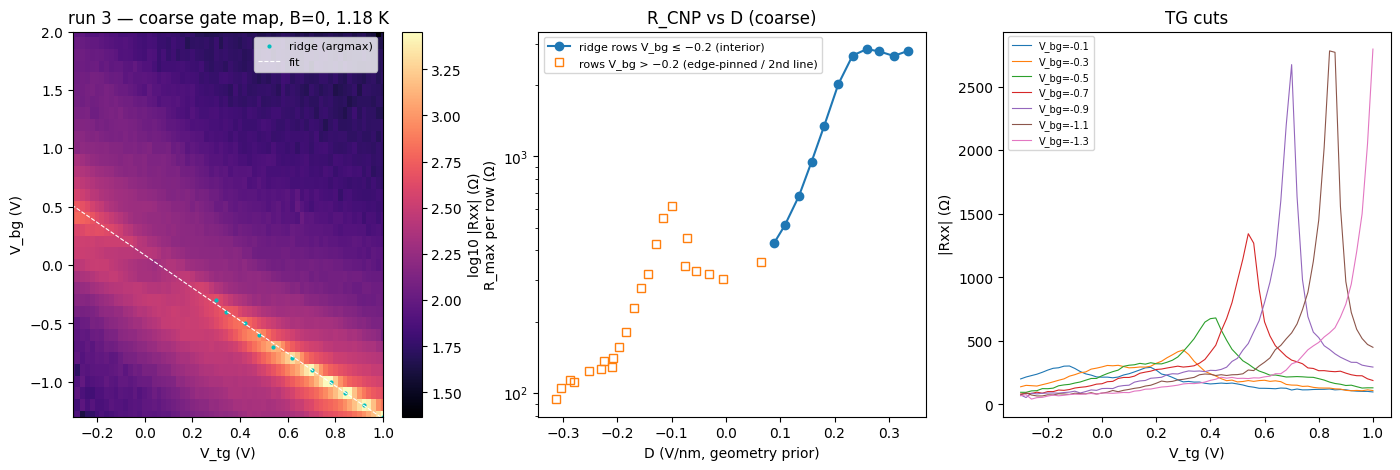

In [10]:
from sharpelab_nb.gates import stack_capacitance, calc_nD
fan = fan_grids(g); rg = resistance_grids(fan)
R = np.abs(rg.R["sr1"]); vb = fan.slow; vt = fan.grid("k_2400_tg_volt")[0]
c_tg = stack_capacitance([(9.5, 3)]); c_bg = stack_capacitance([(11, 3), (0, 3.9)])
# ridge (argmax per row) where the CNP line is interior to the box: rows V_bg <= -0.2
ridge = np.array([(vb[i], vt[np.argmax(R[i])], R[i].max()) for i in range(fan.nrows)])
m = (ridge[:, 0] <= -0.2)
p = np.polyfit(ridge[m, 0], ridge[m, 1], 1)
print(f"CNP line (rows V_bg <= -0.2): V_tg = {p[1]:+.3f} {p[0]:+.3f}*V_bg  ->  c_bg/c_tg = {-p[0]:.3f} (geometry prior 0.864)")
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
pm = ax[0].pcolormesh(vt, vb, np.log10(R), shading="nearest", cmap="magma"); fig.colorbar(pm, ax=ax[0], label="log10 |Rxx| (Ω)")
ax[0].plot(ridge[m, 1], ridge[m, 0], "c.", ms=4, label="ridge (argmax)")
ax[0].plot(p[1] + p[0] * vb, vb, "w--", lw=0.8, label="fit"); ax[0].set_xlim(vt.min(), vt.max()); ax[0].set_ylim(vb.min(), vb.max())
ax[0].set_xlabel("V_tg (V)"); ax[0].set_ylabel("V_bg (V)"); ax[0].legend(fontsize=8); ax[0].set_title("run 3 — coarse gate map, B=0, 1.18 K")
n_r, D_r = calc_nD(ridge[:, 1], ridge[:, 0], c_tg, c_bg)
ax[1].semilogy(D_r[m], ridge[m, 2], "o-", label="ridge rows V_bg ≤ −0.2 (interior)")
ax[1].semilogy(D_r[~m], ridge[~m, 2], "s", mfc="none", label="rows V_bg > −0.2 (edge-pinned / 2nd line)")
ax[1].set_xlabel("D (V/nm, geometry prior)"); ax[1].set_ylabel("R_max per row (Ω)"); ax[1].legend(fontsize=8); ax[1].set_title("R_CNP vs D (coarse)")
for i in [21, 23, 25, 27, 29, 31, 33]:
    ax[2].plot(vt, R[i], lw=0.8, label=f"V_bg={vb[i]:+.1f}")
ax[2].set_xlabel("V_tg (V)"); ax[2].set_ylabel("|Rxx| (Ω)"); ax[2].legend(fontsize=7); ax[2].set_title("TG cuts")
for i in range(fan.nrows):
    if i % 3 == 0 or ridge[i, 2] > 500:
        print(f"V_bg={vb[i]:+.2f}  V_tg*={ridge[i,1]:+.2f}  R_max={ridge[i,2]:6.0f} Ω  D_geo={D_r[i]:+.3f} V/nm")


**Read (run 3):** one sharp CNP ridge crosses the whole box, **V_tg ≈ 0.10 − 0.69·V_bg** (fit on rows V_bg ≤ −0.2 where the maximum is interior; run 1's +0.12 V peak lies on it, run 0's −0.2 V hump does not). Slope gives **c_bg/c_tg ≈ 0.69**, 20 % below the 0.864 thickness prior — the geometry-based n, D scales carry that error until the Landau fan fixes the absolute scale. Along the ridge R_CNP grows from ≈320 Ω at D ≈ 0 to ≈2.8 kΩ by D ≈ +0.25 V/nm and then **saturates** (2.7–2.85 kΩ from +0.23 to +0.34 V/nm) — a ×9 increase, nowhere near insulating at 1.18 K. On the negative-D side (rows V_bg 0.3–0.5, ridge at the V_tg = −0.3 edge, D ≈ −0.07…−0.12) R_max is 450–620 Ω vs 430–510 Ω at the mirrored +D — consistent with D-symmetric within this coarse sampling. A second, parallel, weaker ridge (~300–350 Ω, D-flat between −0.03 and −0.08 V/nm) runs ≈0.4 V lower in V_bg (Δn ≈ −0.5e12 cm⁻² by geometry): either a second doping region between B_1 and B_2 or a hole-side band feature; it does not move relative to the main line so far. Gate currents flat (I_tg −90 pA offset, I_bg +25 pA), I_drain 9.78–9.98 nA. **Lean after this step: the D-dependence (modest, saturating, symmetric) reads Bernal-like (ABAB); ABCA's exponential gap opening is absent up to +0.34 V/nm.** Run 4 (fine band map) quantifies R_CNP(D) and the ±D comparison.

## Run 4 — fine band map along the CNP line (plan step 3)

Why: R_CNP(D) at 5 mV TG resolution, the peak width, the D ≈ 0 point (D_offset), and the R(−D)/R(+D) comparison free of the coarse map's edge-pinning.

run 4
  type:    1D sweep
  recipe:  cnp-band-map
  tags:    multisweep [k_bg.volt, k_tg.volt]: 39 rows V_bg -1.3..0.6 @50mV x TG window +/-0.15 V @5mV about V_tg=0.10-0.691*V_bg (run 3 ridge), box-clipped (2199 pts); delay 0.5 s, tau 100 ms; V_si=0, B=0; I_bias 10 nA
  rows:    2199 of 2 (2199/2 (no interrupt flag, row count differs))


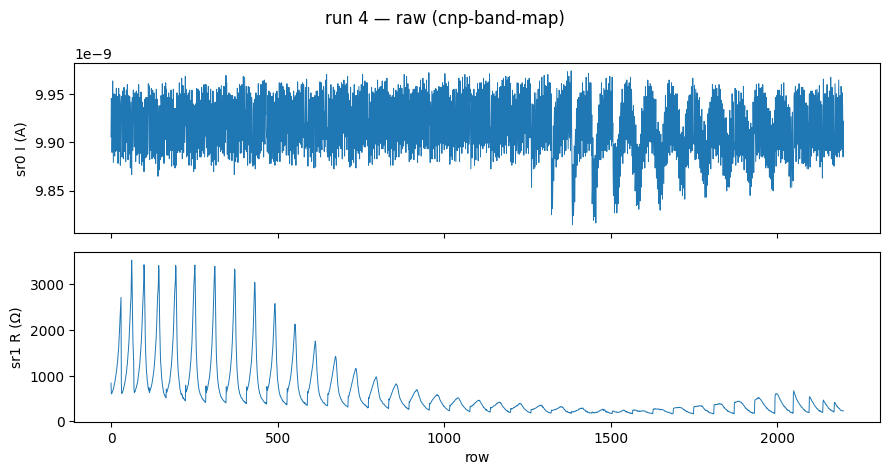

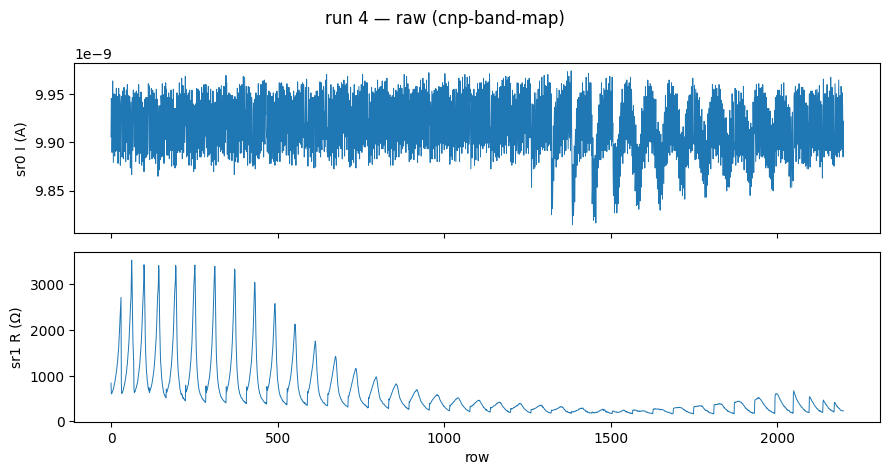

In [11]:
g = run(4)
print(summarize_run(g))
plot_raw(g)


CNP line (hole-side rows): V_tg = +0.061 -0.713*V_bg -> c_bg/c_tg = 0.713
R_CNP minimum 248 Ω at (V_tg, V_bg) = (+0.110, +0.00), D_geo = +0.017 V/nm  -> D_offset
|D-D0| = 0.030: R(-D)/R(+D) = 0.82
|D-D0| = 0.041: R(-D)/R(+D) = 0.78
|D-D0| = 0.051: R(-D)/R(+D) = 0.86
|D-D0| = 0.062: R(-D)/R(+D) = 0.87
|D-D0| = 0.072: R(-D)/R(+D) = 0.89
|D-D0| = 0.083: R(-D)/R(+D) = 0.88
|D-D0| = 0.093: R(-D)/R(+D) = 0.89
|D-D0| = 0.104: R(-D)/R(+D) = 0.89
|D-D0| = 0.114: R(-D)/R(+D) = 0.87
|D-D0| = 0.125: R(-D)/R(+D) = 0.84
|D-D0| = 0.135: R(-D)/R(+D) = 0.54
|D-D0| = 0.146: R(-D)/R(+D) = 0.39
R_CNP at D-D0 = +0.10, +0.20, +0.30: ['569 Ω', '2498 Ω', '3484 Ω']


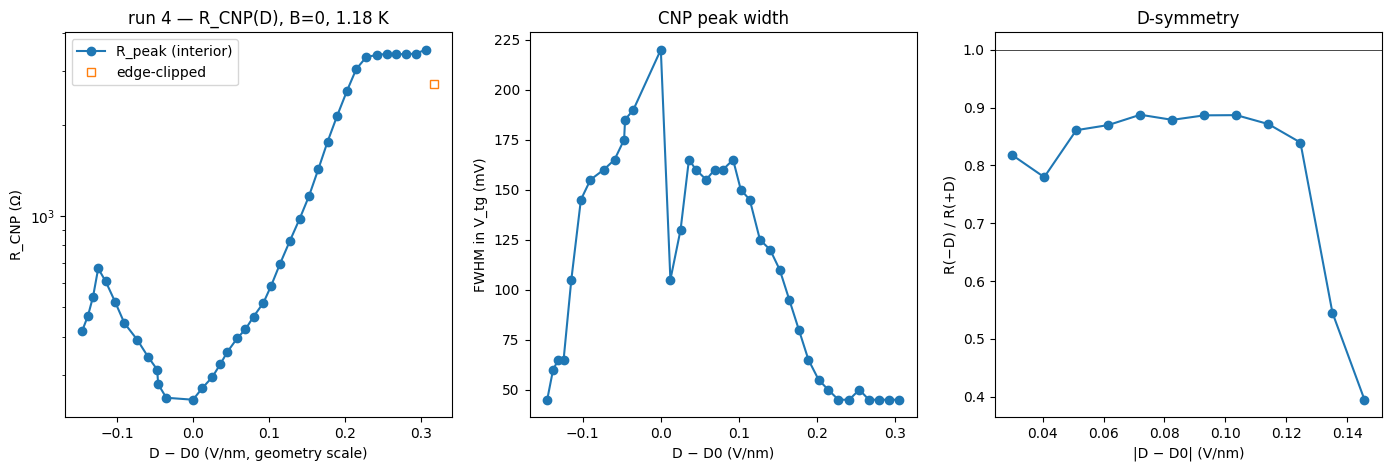

In [13]:
from sharpelab_nb.gates import stack_capacitance, calc_nD
mc = g.meta["measurement_config"]
vb = g.col("k_2400_bg_volt"); vt = g.col("k_2400_tg_volt")
I = g.col("sr0_X") / mc["sr0_gain"]; R = np.abs(g.col("sr1_X") / I)
c_tg = stack_capacitance([(9.5, 3)]); c_bg = stack_capacitance([(11, 3), (0, 3.9)])
rows = np.unique(vb); tab = []
for v in rows:
    m = np.isclose(vb, v); x, y = vt[m], R[m]; j = np.argmax(y)
    half = (y[j] + y.min()) / 2; above = x[y >= half]
    tab.append((v, x[j], y[j], (above.max() - above.min()) * 1e3, j in (0, len(x) - 1)))
tab = np.array(tab, dtype=float); ok = tab[:, 4] == 0
_, D = calc_nD(tab[:, 1], tab[:, 0], c_tg, c_bg)
hole = ok & (tab[:, 0] <= -0.2); p = np.polyfit(tab[hole, 0], tab[hole, 1], 1)
i0 = np.argmin(np.where(ok, tab[:, 2], np.inf)); D0 = D[i0]
print(f"CNP line (hole-side rows): V_tg = {p[1]:+.3f} {p[0]:+.3f}*V_bg -> c_bg/c_tg = {-p[0]:.3f}")
print(f"R_CNP minimum {tab[i0,2]:.0f} Ω at (V_tg, V_bg) = ({tab[i0,1]:+.3f}, {tab[i0,0]:+.2f}), D_geo = {D0:+.3f} V/nm  -> D_offset")
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].semilogy(D[ok] - D0, tab[ok, 2], "o-", label="R_peak (interior)"); ax[0].semilogy(D[~ok] - D0, tab[~ok, 2], "s", mfc="none", label="edge-clipped")
ax[0].set_xlabel("D − D0 (V/nm, geometry scale)"); ax[0].set_ylabel("R_CNP (Ω)"); ax[0].legend(); ax[0].set_title("run 4 — R_CNP(D), B=0, 1.18 K")
ax[1].plot(D[ok] - D0, tab[ok, 3], "o-"); ax[1].set_xlabel("D − D0 (V/nm)"); ax[1].set_ylabel("FWHM in V_tg (mV)"); ax[1].set_title("CNP peak width")
# ±D comparison on the common range
Dp = D[ok] - D0; Rp = tab[ok, 2]; pos = Dp > 0.02; neg = Dp < -0.02
dd = np.linspace(0.03, min(Dp.max(), -Dp.min()), 12)
_op = np.argsort(Dp[pos]); _on = np.argsort(-Dp[neg])
Rpos = np.interp(dd, Dp[pos][_op], Rp[pos][_op]); Rneg = np.interp(dd, (-Dp[neg])[_on], Rp[neg][_on])
ax[2].plot(dd, Rneg / Rpos, "o-"); ax[2].axhline(1, color="k", lw=0.5); ax[2].set_xlabel("|D − D0| (V/nm)"); ax[2].set_ylabel("R(−D) / R(+D)"); ax[2].set_title("D-symmetry")
for d_, rr in zip(dd, Rneg / Rpos):
    print(f"|D-D0| = {d_:.3f}: R(-D)/R(+D) = {rr:.2f}")
print("R_CNP at D-D0 = +0.10, +0.20, +0.30:", [f"{np.interp(x, Dp[pos][_op], Rp[pos][_op]):.0f} Ω" for x in (0.10, 0.20, 0.30)])


**Read (run 4):** the ridge refit on the hole side gives V_tg ≈ 0.06 − 0.71·V_bg (**c_bg/c_tg ≈ 0.71**). R_CNP has a clean minimum of **248 Ω at (V_tg, V_bg) = (0.11, 0.00)**, i.e. D_geo ≈ +0.017 V/nm — that is the session's D = 0 reference (D_offset). From there R_CNP rises on both sides: referenced to D0, **R(−D)/R(+D) ≈ 0.85–0.90 over |D−D0| = 0.04–0.125 V/nm** (the reachable negative range; beyond that the −D rows are box-clipped), i.e. a ~10–15 % asymmetry, within what a ±0.01 V/nm error on D0 produces — no sign of the strong D-sign asymmetry a non-centrosymmetric stacking would give. On the +D side it climbs ×14 (569 Ω at +0.10, 2.5 kΩ at +0.20) to **≈3.4 kΩ by D−D0 ≈ +0.23 V/nm and then saturates flat** to the box edge (+0.32). The peak width shrinks from ≈150–220 mV in V_tg (≈0.3e12 cm⁻², broad and low: a two-carrier, semimetal-like neutrality region) near D0 to a sharp **45 mV** (≈0.08e12) once gapped, and the R-maximum position kinks off the straight line near D0 (argmax of a broad two-carrier peak, not n = 0). Gate currents flat, I_drain 9.9 nA. **Stacking read so far:** essentially D-symmetric → not ABCB; no exponential/insulating gap up to +0.32 V/nm (3.4 kΩ, saturating) → not ABCA-like; broad low CNP at D0 plus a modest, saturating D-gap → **ABAB-consistent**. Open: whether the 3.4 kΩ plateau is activated (gap) or a parallel path — the T ladder (step 5); and the LL structure — the fan (step 4).

## Run 6 — Landau fan at D ≈ 0, 0.6 → 8 T (plan step 4a; measure-while-ramping)

Why: the ν sequence near neutrality is the LL-structure discriminator (ABAB: bilayer-like sectors, robust ν = ±4, crossings; ABCA: 16-fold zero-energy manifold, first gaps at ν = ±8), and the ν-line slopes calibrate the absolute n scale. (Run 5 is an empty stub — int64 metadata bug.)

run 6
  type:    2D sweep
  recipe:  landau-fan-up
  tags:    multimegasweep fan_row x [k_tg.volt,k_bg.volt] along V_tg=+0.110+0.71*(V_bg-(+0.000)), V_bg -0.565..+1.250 @15mV (122 pts); magnet start_field_ramp(8.0) then 38 rows, B read per point; fast_delay 0.5 s, tau 100 ms; V_si=0; I_bias 10 nA
  rows:    4636


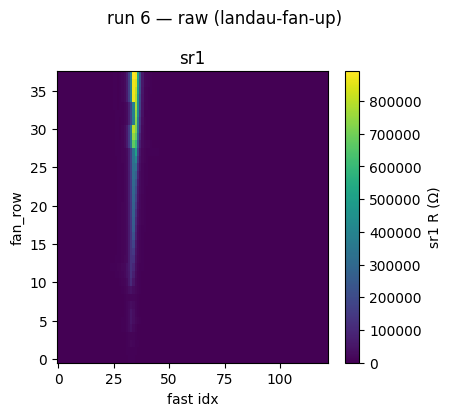

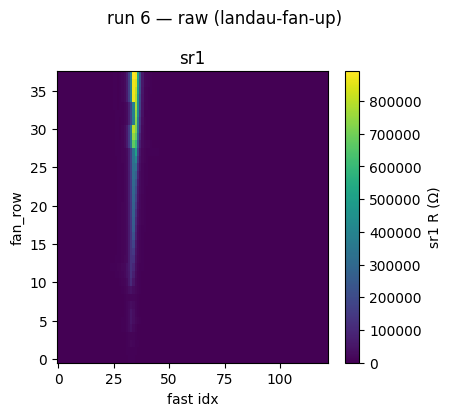

In [14]:
g = run(6)
print(summarize_run(g))
plot_raw(g, channels=["sr1"])


absolute n calibration from the nu fan: n = 0.820 x n_geo (minima cluster at multiples of 4)
  nu=-12:   7 minima, B 2.2-3.4 T
  nu= -8:   9 minima, B 1.4-5.0 T
  nu= -4:  13 minima, B 1.2-8.0 T
  nu= +4:  29 minima, B 2.2-8.0 T
  nu= +8:  16 minima, B 1.9-8.0 T
  nu=+12:  26 minima, B 1.7-8.0 T
  nu=+16:  24 minima, B 1.3-7.2 T
  nu=+20:  19 minima, B 2.1-5.8 T


C:\Users\DGG\AppData\Local\Temp\ipykernel_23772\453322895.py:29: UserWarning: The input coordinates to pcolormesh are interpreted as cell centers, but are not monotonically increasing or decreasing. This may lead to incorrectly calculated cell edges, in which case, please supply explicit cell edges to pcolormesh.
  pm = ax[0].pcolormesh(ng*scale, Bg, np.log10(Rg), shading="nearest", cmap="magma"); fig.colorbar(pm, ax=ax[0], label="log10 |Rxx| (Ω)")


Text(0.5, 1.0, 'ν=0 growth — note dips ≈2.4 T and ≈7.2 T')

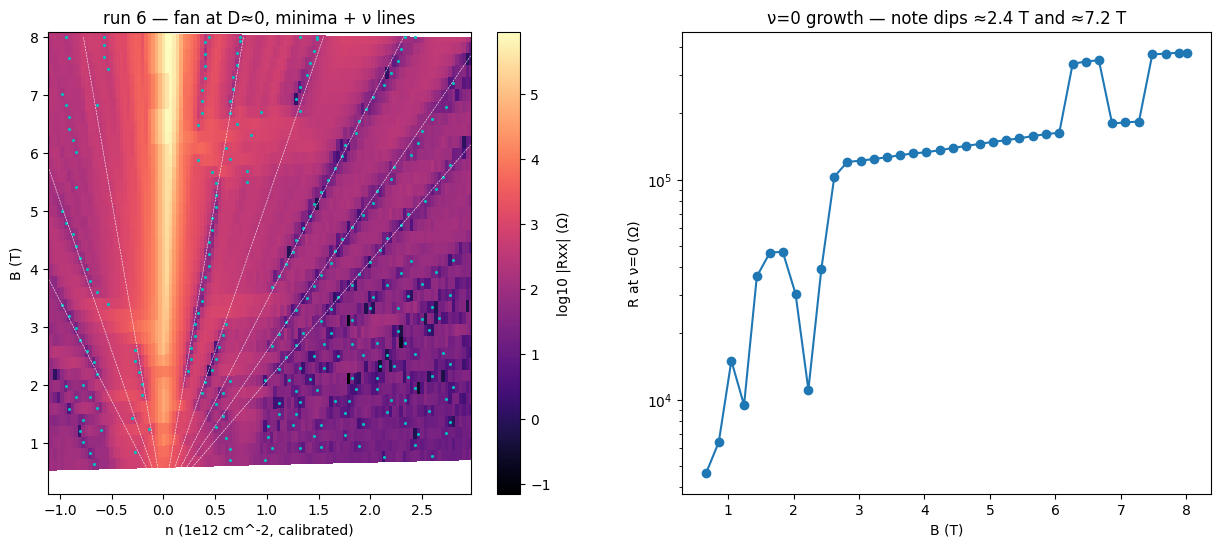

In [15]:
# nu-line extraction and absolute n calibration (same as hera_scratch/ana_fan_nu.py)
import scipy.constants as cst
from scipy.signal import argrelmin
from sharpelab_nb.gates import stack_capacitance, calc_nD
mc = g.meta["measurement_config"]
vt, vb, B = g.col("k_2400_tg_volt"), g.col("k_2400_bg_volt"), g.col("magnet_field")
I = g.col("sr0_X") / mc["sr0_gain"]; R = np.abs(g.col("sr1_X") / I)
nfast = len(g.meta["fast_setpoints"][0]); nrows = len(R) // nfast
c_tg = stack_capacitance([(9.5, 3)]); c_bg = stack_capacitance([(11, 3), (0, 3.9)])
n_geo, _ = calc_nD(vt, vb, c_tg, c_bg)
Rg = R[:nrows*nfast].reshape(nrows, nfast); Bg = B[:nrows*nfast].reshape(nrows, nfast); ng = n_geo[:nrows*nfast].reshape(nrows, nfast)
pts = []
for i in range(nrows):
    ls = np.convolve(np.log10(np.maximum(Rg[i], 1e-1)), np.ones(3)/3, mode="same")
    for j in argrelmin(ls, order=3)[0]:
        prom = max(ls[max(0, j-6):j+7]) - ls[j]
        if prom > 0.25 and 3 < j < nfast-4 and abs(ng[i, j]) > 0.12:
            pts.append((Bg[i, j], ng[i, j]))
pts = np.array(pts)
nu_geo = pts[:, 1] * 1e16 / (cst.e * pts[:, 0] / cst.h)
best = min(((sc, np.mean(np.minimum(np.abs(nu_geo*sc - np.round(nu_geo*sc/4)*4), 1.0)**2)) for sc in np.arange(0.7, 1.45, 0.005)), key=lambda t: t[1])
scale = best[0]; nu = nu_geo * scale
print(f"absolute n calibration from the nu fan: n = {scale:.3f} x n_geo (minima cluster at multiples of 4)")
for t in [-12, -8, -4, 4, 8, 12, 16, 20]:
    sel = np.abs(nu - t) < 1.2
    if sel.sum():
        print(f"  nu={t:+3d}: {sel.sum():3d} minima, B {pts[sel,0].min():.1f}-{pts[sel,0].max():.1f} T")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pm = ax[0].pcolormesh(ng*scale, Bg, np.log10(Rg), shading="nearest", cmap="magma"); fig.colorbar(pm, ax=ax[0], label="log10 |Rxx| (Ω)")
ax[0].plot(pts[:, 1]*scale, pts[:, 0], "c.", ms=2.5)
for t in [-12, -8, -4, 4, 8, 12, 16, 20]:
    bb = np.linspace(0.5, Bg.max(), 40); ax[0].plot(t*cst.e*bb/cst.h*1e-16, bb, "w--", lw=0.4)
ax[0].set_xlim((ng*scale).min(), (ng*scale).max()); ax[0].set_xlabel("n (1e12 cm^-2, calibrated)"); ax[0].set_ylabel("B (T)")
ax[0].set_title("run 6 — fan at D≈0, minima + ν lines")
i0 = np.argmin(np.abs(ng - 0.0), axis=1)
ax[1].semilogy(Bg[np.arange(nrows), i0], Rg[np.arange(nrows), i0], "o-")
ax[1].set_xlabel("B (T)"); ax[1].set_ylabel("R at ν=0 (Ω)"); ax[1].set_title("ν=0 growth — note dips ≈2.4 T and ≈7.2 T")


**Read (run 6):** clean QH fan on both carrier signs. 257 Rxx-minima candidates fit a single scale factor: **n = 0.82 × n_geo** (geometry-prior capacitances overestimate by 18 %, consistent with the c_bg/c_tg = 0.71 vs 0.864 finding). With that scale the minima cluster at **ν = −12, −8, −4, +4, +8, +12, +16, +20** — spacing 4, i.e. spin×valley degenerate single-particle LLs. **ν = ±4 are robust and tracked to the lowest resolvable fields (ν = −4 from 1.2 T, ν = +8 from 1.9 T)** — the sequence of a Bernal-like band structure with 4-fold LLs from bilayer-type sectors, not the 16-fold zero-energy manifold of ABCA (which would leave ν = ±4 absent at low B, first gaps at ±8). The **ν = 0 state grows insulating with B but non-monotonically: dips at ≈2.2–2.5 T (47 kΩ → 39 kΩ) and ≈6.7–7.3 T (794 kΩ → 775 kΩ)** — gap closings/reopenings = LL crossings inside the zero-energy manifold as B rescales the two sectors, again characteristic of Bernal (ABAB) multilayers; ABCA's ν = 0 grows monotonically. T_sample 1.18 → 1.28 K over the ramp (eddy heating, accepted). **Stacking read: ABAB reinforced (LL sequence + ν=0 crossings + all of runs 3/4).** Remaining: run 7 (fan at D−D0 ≈ +0.20) and the T ladder (activation gaps).

## Run 7 — Landau fan at D−D0 ≈ +0.20 V/nm, 8 → 0 T (plan step 4b)

Why: the LL structure of the *gapped* state (the R_CNP(D) plateau knee), on the descent — never re-traverse the field. Also tests whether the B = 0 plateau is a parallel conduction path (it would imprint its own LL signature).

run 7
  type:    2D sweep
  recipe:  landau-fan-down
  tags:    multimegasweep fan_row x [k_tg.volt,k_bg.volt] along V_tg=+0.657+0.71*(V_bg-(-0.850)), V_bg -1.298..-0.367 @7.5mV (125 pts); magnet start_field_ramp(0.0) from 8 T then 40 rows, B read per point; fast_delay 0.5 s, tau 100 ms; V_si=0; I_bias 10 nA
  rows:    5000


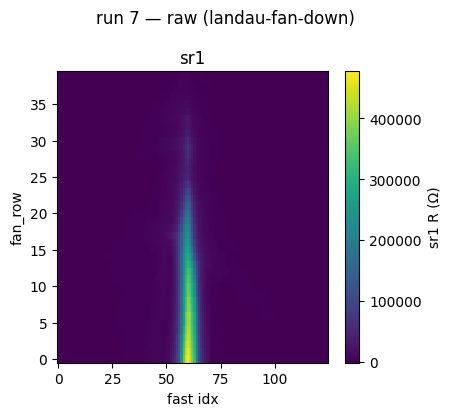

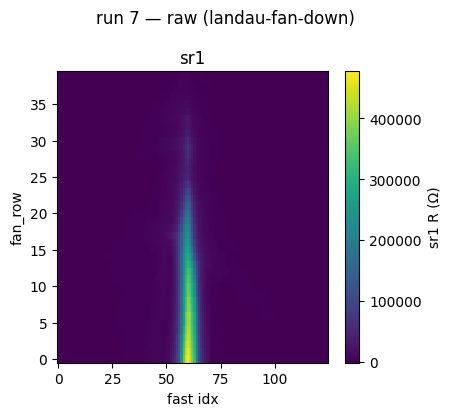

In [16]:
g = run(7)
print(summarize_run(g))
plot_raw(g, channels=["sr1"])


204 minima; filling assignments with the run-6 scale (0.82):
  nu= -6:  17 minima, B 2.7-8.0 T
  nu= -4:  16 minima, B 5.0-8.0 T
  nu= -2:  23 minima, B 5.4-8.0 T
  nu= +2:  19 minima, B 2.8-7.9 T
  nu= +4:  19 minima, B 2.6-7.8 T
  nu= +6:   7 minima, B 2.4-6.5 T
  nu= +8:  10 minima, B 2.0-5.1 T
  nu=+12:   6 minima, B 2.0-2.9 T


Text(0.5, 1.0, 'ν=0 growth — monotonic at finite D')

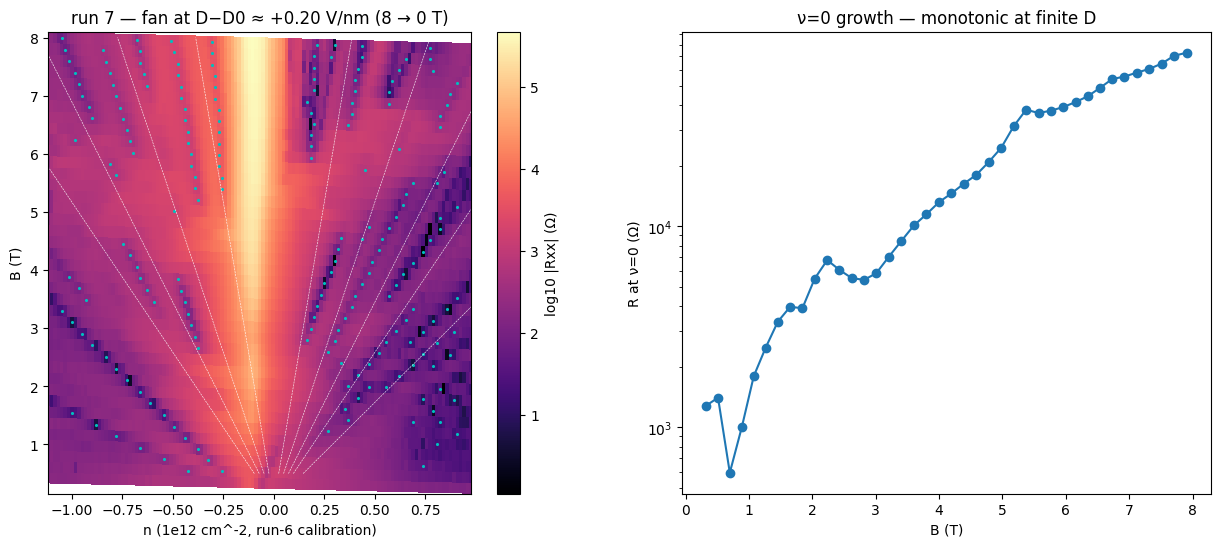

In [17]:
# run 7: minima with the run-6 absolute scale (n = 0.82 x n_geo); nu=0 growth at D-D0 ~ +0.20
import scipy.constants as cst
from scipy.signal import argrelmin
from sharpelab_nb.gates import stack_capacitance, calc_nD
mc = g.meta["measurement_config"]
vt, vb, B = g.col("k_2400_tg_volt"), g.col("k_2400_bg_volt"), g.col("magnet_field")
I = g.col("sr0_X") / mc["sr0_gain"]; R = np.abs(g.col("sr1_X") / I)
nfast = len(g.meta["fast_setpoints"][0]); nrows = len(R) // nfast
c_tg = stack_capacitance([(9.5, 3)]); c_bg = stack_capacitance([(11, 3), (0, 3.9)])
n_geo, _ = calc_nD(vt, vb, c_tg, c_bg)
Rg = R[:nrows*nfast].reshape(nrows, nfast); Bg = B[:nrows*nfast].reshape(nrows, nfast); ng = n_geo[:nrows*nfast].reshape(nrows, nfast)
SCALE = 0.82   # run 6
pts = []
for i in range(nrows):
    ls = np.convolve(np.log10(np.maximum(Rg[i], 1e-1)), np.ones(3)/3, mode="same")
    for j in argrelmin(ls, order=3)[0]:
        if max(ls[max(0, j-6):j+7]) - ls[j] > 0.25 and 3 < j < nfast-4 and abs(ng[i, j]) > 0.10:
            pts.append((Bg[i, j], ng[i, j]))
pts = np.array(pts); nu = pts[:, 1] * 1e16 / (cst.e * pts[:, 0] / cst.h) * SCALE
print(f"{len(pts)} minima; filling assignments with the run-6 scale ({SCALE}):")
for t in [-8, -6, -4, -2, 2, 4, 6, 8, 12]:
    sel = np.abs(nu - t) < 0.8
    if sel.sum():
        print(f"  nu={t:+3d}: {sel.sum():3d} minima, B {pts[sel,0].min():.1f}-{pts[sel,0].max():.1f} T")
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
pm = ax[0].pcolormesh(ng*SCALE, Bg, np.log10(Rg), shading="nearest", cmap="magma"); fig.colorbar(pm, ax=ax[0], label="log10 |Rxx| (Ω)")
ax[0].plot(pts[:, 1]*SCALE, pts[:, 0], "c.", ms=2.5)
for t in [-8, -6, -4, -2, 2, 4, 6, 8, 12]:
    bb = np.linspace(0.5, Bg.max(), 40); ax[0].plot(t*cst.e*bb/cst.h*1e-16, bb, "w--", lw=0.4)
ax[0].set_xlabel("n (1e12 cm^-2, run-6 calibration)"); ax[0].set_ylabel("B (T)"); ax[0].set_xlim((ng*SCALE).min(), (ng*SCALE).max())
ax[0].set_title("run 7 — fan at D−D0 ≈ +0.20 V/nm (8 → 0 T)")
i0 = np.argmin(np.abs(ng), axis=1)
ax[1].semilogy(Bg[np.arange(nrows), i0], Rg[np.arange(nrows), i0], "o-")
ax[1].set_xlabel("B (T)"); ax[1].set_ylabel("R at ν=0 (Ω)"); ax[1].set_title("ν=0 growth — monotonic at finite D")


**Read (run 7):** with the run-6 calibration (n = 0.82·n_geo, no free parameters), the 204 minima land at **ν = ±2, ±4, +6, ±8, +12** — the D ≈ 0 fan's 4-fold steps are split into **steps of 2** at finite D, i.e. the displacement field lifts the valley/layer degeneracy of bilayer-like LLs (ν = −2, +2 tracked over 2.8–8 T). The **ν = 0 state now grows monotonically** (1 kΩ at 0.9 T → 73 kΩ at 7.9 T) — no crossings, as expected once D polarizes the zero-energy manifold; contrast the dips at 2.4 / 7.2 T in run 6. The B → 0 limit of the ν = 0 line extrapolates smoothly to the few-kΩ B = 0 plateau (2.6 kΩ at this D), and the whole n-window shows ordinary QH behavior — no second electronic system, so the B = 0 saturation is a property of the gapped channel (finite sub-gap conduction at 1.2 K), not an obvious parallel path; the T ladder decides. T_sample 1.18–1.28 K. **Stacking read: Bernal (ABAB) phenomenology again — D-split 2-fold LL sequence, monotonic polarized ν = 0.**

## Runs 8–18 — temperature ladder of R_CNP at five D values, B = 0 (plan step 5)

Why: the size of the D-induced gap by thermal activation — the last ABAB/ABCA discriminator, and the test of whether the B = 0 R_CNP(D) plateau is an activated gap or residual/parallel conduction. One run per T point (base → 50 K, set_both ratio 0.95, hover acceptance; every settle accepted stable).

Arrhenius (T >= 8 K), gap = 2 x slope:
  D−D0=-0.11: R(1.2K)=613 Ω, R(50K)=647 Ω, Δ = -0.2 meV
  D−D0=+0.00: R(1.2K)=243 Ω, R(50K)=376 Ω, Δ = -0.8 meV
  D−D0=+0.10: R(1.2K)=586 Ω, R(50K)=631 Ω, Δ = -0.2 meV
  D−D0=+0.19: R(1.2K)=2168 Ω, R(50K)=945 Ω, Δ = 1.2 meV
  D−D0=+0.28: R(1.2K)=3386 Ω, R(50K)=1270 Ω, Δ = 1.8 meV


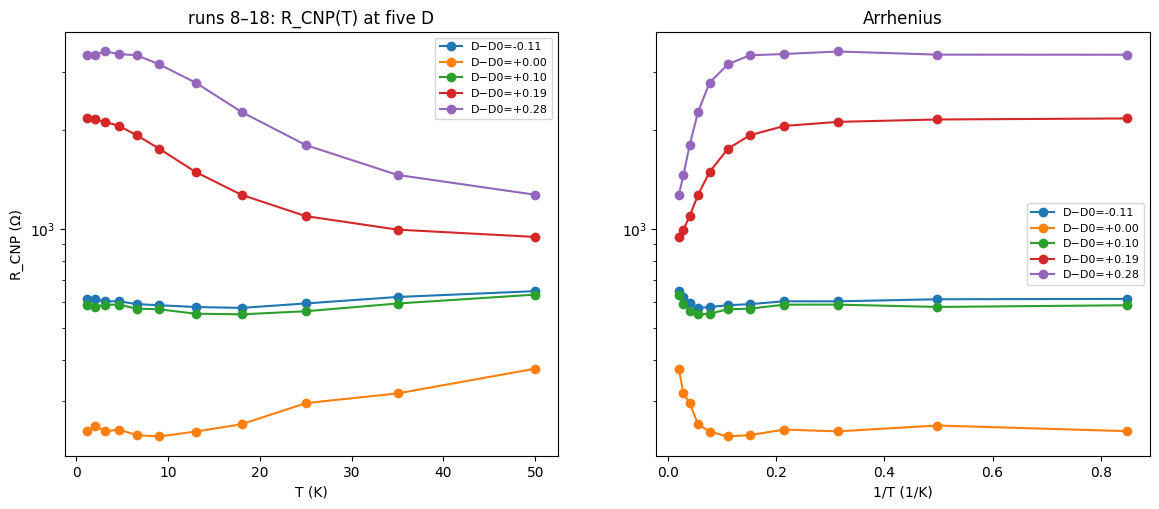

In [18]:
# cnp-t-ladder: runs 8-18, one per T point; peak R per D window; Arrhenius on the high-T branch
import scipy.constants as cst
D_LAB = {0.40: -0.11, 0.00: 0.0, -0.45: +0.10, -0.80: +0.19, -1.15: +0.28}
data = {}
for rid in range(8, 19):
    g = run(rid)
    if g.recipe != "cnp-t-ladder":
        continue
    mc = g.meta["measurement_config"]
    vb = g.col("k_2400_bg_volt"); I = g.col("sr0_X") / mc["sr0_gain"]
    R = np.abs(g.col("sr1_X") / I); Tm = np.median(g.col("T_sample"))
    for v in np.unique(np.round(vb, 3)):
        m = np.isclose(np.round(vb, 3), v)
        data.setdefault(float(v), []).append((Tm, float(np.max(R[m]))))
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
print("Arrhenius (T >= 8 K), gap = 2 x slope:")
for v in sorted(data, reverse=True):
    arr = np.array(sorted(data[v])); lab = D_LAB.get(round(v, 2), v)
    ax[0].semilogy(arr[:, 0], arr[:, 1], "o-", label=f"D−D0={lab:+.2f}")
    ax[1].semilogy(1 / arr[:, 0], arr[:, 1], "o-", label=f"D−D0={lab:+.2f}")
    hi = arr[arr[:, 0] >= 8]
    p = np.polyfit(1 / hi[:, 0], np.log(hi[:, 1]), 1)
    print(f"  D−D0={lab:+.2f}: R(1.2K)={arr[0,1]:.0f} Ω, R(50K)={arr[-1,1]:.0f} Ω, Δ = {2*p[0]*cst.k/cst.e*1e3:.1f} meV")
ax[0].set_xlabel("T (K)"); ax[0].set_ylabel("R_CNP (Ω)"); ax[0].legend(fontsize=8); ax[0].set_title("runs 8–18: R_CNP(T) at five D")
ax[1].set_xlabel("1/T (1/K)"); ax[1].set_title("Arrhenius"); ax[1].legend(fontsize=8)


**Read (runs 8–18):** R_CNP(T) is **flat below ~7 K at every D**, then falls gently at the gapped points: at D−D0 = +0.28 V/nm, 3.39 kΩ (1.2 K) → 1.27 kΩ (50 K), Arrhenius slope on T ≥ 8 K giving **Δ ≈ 1.8 meV**; at +0.19, Δ ≈ 1.2 meV; at ±0.10 and at D0 the CNP is **non-activated** (R flat or slightly rising with T — metallic/semimetallic). The gap scale is **meV**, weakly D-dependent, with a large residual R(T→∞) ≈ 1.1 kΩ — thermally assisted conduction over a small, saturating gap. ABCA at 0.2–0.3 V/nm would show tens of meV (orders of magnitude in R by 50 K); observed is a factor 2.7. Also fixes the plateau question from runs 4/7: the saturation is a property of the small-gap channel (finite sub-gap and thermally assisted conduction), not an external shunt. **Ladder closes the evidence set: ABAB.**

# FINAL CALL — vti-02 stacking order (session 2026-08-23/24)

## Per-region verdict
- **Pair B_1–B_2 (sr1; source T_0 → drain B_3) — the only measured region: ABAB (Bernal), strong.**
- No other region measurable this cooldown: T_1–T_4 dead as provided, sr2/sr3 not connected — no second contact pair, no Rxy.

## Evidence (session runs only)
1. **R_CNP(D), B = 0** (data/3, data/4): minimum 248 Ω at D0 = (V_tg, V_bg) = (0.11, 0.00); rises ×14 to ≈3.4 kΩ by D−D0 ≈ +0.23 V/nm and **saturates** to the box edge (+0.32). ABCA would be ≫MΩ and exponential in D at 1.2 K.
2. **D-symmetry** (data/4): R(−D)/R(+D) = 0.85–0.90 over |D−D0| = 0.04–0.125 V/nm — inversion-symmetric response → excludes ABCB (no inversion/mirror).
3. **Landau fan at D ≈ 0** (data/6): minima at ν = −12, −8, −4, +4, +8, +12, +16, +20 (**4-fold steps; ν = ±4 robust to the lowest resolvable B**) — Bernal two-sector LL structure, not ABCA's 16-fold zero-energy manifold (ν = ±8-first). **ν = 0 grows non-monotonically** (dips at ≈2.4 and ≈7.2 T: zero-manifold LL crossings — a Bernal-multilayer fingerprint).
4. **Landau fan at D−D0 ≈ +0.20** (data/7): the sequence splits to **steps of 2** (ν = ±2, ±4, +6, ±8) and ν = 0 becomes monotonic (73 kΩ at 8 T) — D-polarized bilayer-like LLs.
5. **Activation** (data/8–18): Δ ≈ 1.8 meV at D−D0 = +0.28, 1.2 meV at +0.19, ≈0 at |D−D0| ≤ 0.11; residual R(∞) ≈ 1.1 kΩ. meV-scale, weakly D-dependent gap ↔ Bernal; not ABCA's tens of meV.
6. **Calibration** (this session): c_bg/c_tg = 0.71 (data/3/4 CNP-line slope), n = 0.82 × n_geo (data/6 ν-line fit); all n, D values above are on this session's own scale (geometry-prior D units).

## Confidence and hedges
- **Would overturn:** an activation gap ≫10 meV at reachable D (excluded by data/8–18); strongly D-asymmetric transport (excluded by data/4 within the ±0.125 V/nm overlap); a ν = ±8-first LL sequence (excluded by data/6).
- **Not measured:** any second region (all spare contacts dead as provided — a boundary between stacking domains elsewhere in the flake is invisible to this pair); Rxy (no wired probe pair); |D−D0| > 0.32 V/nm; T < 1.17 K; the −D side beyond −0.13 V/nm (box limit).
- **Secondary feature:** a weak parallel resistance line ≈0.4 V below the CNP line in V_bg (≈−0.5e12 cm⁻²; data/1, data/3) is D-flat, ≈300 Ω, contributes no LL signature of its own in data/6/7 — most consistent with a contact-doped strip near a probe, not a second stacking domain; it does not affect the verdict.
- ABCB with accidentally compensated asymmetry cannot be excluded by symmetry alone, but the observed 4-fold → 2-fold LL evolution and ν = 0 crossing pattern match ABAB specifically.